# Generación de bases *Bracket*, *No Bracket* y *Pre a Home*
### Cruce de audiencias de migración Tigo mediante operaciones de conjuntos sobre la llave MSISDN

| Ficha técnica | |
|:--|:--|
| **Autor** | Daniel Vargas Zapata |
| **Fecha** | Noviembre de 2026 |
| **Contexto** | Campaña de migración de Tigo (Pre a Pos y Pre a Home) |
| **Unidad de análisis** | Línea móvil, identificada por su MSISDN |
| **Herramientas** | Python · pandas · NumPy · Matplotlib |
| **Salidas** | `base no bracket.csv`, `base pre a home.csv` y nueve archivos `bracket_<valor>.csv` (exportados) · resultados de la base consolidada `df_final` documentados en la sección 7.6 |

---

**Contenido**

1. [Carga de las bases de datos](#1.-Carga-de-las-bases-de-datos)
2. [Volumetría de las fuentes](#2.-Volumetría-de-las-fuentes)
3. [Preparación de la llave y utilidades](#3.-Preparación-de-la-llave-y-utilidades)
4. [Cruce I de No Bracket](#4.-Cruce-I-de-No-Bracket)
5. [Cruce II de Pre a Home](#5.-Cruce-II-de-Pre-a-Home)
6. [Cruce III de Bracket](#6.-Cruce-III-de-Bracket)
7. [Consolidación de la base final](#7.-Consolidación-de-la-base-final)
8. [Criterio de selección del bracket](#8.-Criterio-de-selección-del-bracket)
9. [Verificación de consistencia y resumen](#9.-Verificación-de-consistencia-y-resumen)
10. [Limitaciones y recomendaciones](#10.-Limitaciones-y-recomendaciones)

## Objetivo general

Generar, mediante el cruce por la llave **MSISDN** de las audiencias *PRE A POS ADICIONAL* y *PRE A HOME* contra la base *Ecommerce Televentas*, las bases segmentadas **No Bracket**, **Pre a Home** y **Bracket** (esta última consolidada con *PRE A POS*), garantizando trazabilidad, reproducibilidad y consistencia de los conteos en cada etapa del proceso.

## Objetivos específicos

| N.º | Objetivo | Sección |
|:--:|:--|:--:|
| **OE1** | Cargar y cuantificar (volumetría) las fuentes de información: PRE A HOME, PRE A POS, PRE A POS ADICIONAL y Ecommerce Televentas. | 1 – 2 |
| **OE2** | Homogeneizar la llave de cruce (MSISDN) para asegurar que la comparación entre bases sea válida. | 3 |
| **OE3** | Identificar y exportar la base **No Bracket**: registros de PRE A POS ADICIONAL ausentes en Ecommerce Televentas. | 4 |
| **OE4** | Identificar y exportar la base **Pre a Home**: registros de PRE A HOME ausentes en Ecommerce Televentas. | 5 |
| **OE5** | Identificar los registros **Bracket** (presentes en ambas bases) y unirlos mediante un *inner join*. | 6 |
| **OE6** | Consolidar la base final integrando PRE A POS (limpia y de inicio de mes) con los Bracket, seleccionar el bracket de menor valor por MSISDN, exportar un archivo por categoría y verificar sus conteos. | 7 – 8 |
| **OE7** | Representar visualmente los cruces con diagramas de Venn de áreas proporcionales y verificar la consistencia de los conteos. | 4, 5 y 9 |

## Marco conceptual y notación

Sea el MSISDN la llave de identificación de cada línea. Cada fuente se representa como el conjunto de sus MSISDN normalizados:

| Símbolo | Fuente | Variable | Archivo de origen |
|:--:|:--|:--:|:--|
| $H$ | PRE A HOME | `df1` | `PRE A HOME.csv` (carpeta MIGRA) |
| $P$ | PRE A POS (base limpia) | `df2` | `PRE A POS.csv` (carpeta MIGRA) |
| $A$ | PRE A POS ADICIONAL | `df3` | `PRE A POS ADICIONAL.csv` (carpeta MIGRA) |
| $E$ | Ecommerce Televentas | `df4` | `Ecomerce televentas.csv` (carpeta Migra Tigo) |
| $P'$ | PRE A POS (inicio de mes) | `df5` | `PRE A POS.csv` (carpeta Migra Tigo) |

**Definiciones de las bases a generar**

$$\text{No Bracket} = A \setminus E = \{\, m \in A : m \notin E \,\}$$

$$\text{Pre a Home} = H \setminus E = \{\, m \in H : m \notin E \,\}$$

$$\text{Bracket} = A \cap E = \{\, m : m \in A \ \wedge\ m \in E \,\}$$

$$\text{df\_final} = (P \parallel P') \parallel (A \bowtie E)$$

donde $\parallel$ denota la concatenación de filas y $\bowtie$ el *inner join* por MSISDN.

**Flujo metodológico**

```text
H  ──── H \ E ───────────────────────────────────►  base pre a home.csv
A  ──── A \ E ───────────────────────────────────►  base no bracket.csv
A  ──── A ∩ E ──── inner join con E ──┐
                                      ├──►  df_final ──► bracket de menor valor ──► exportación por bracket
P ∥ P′ ───────────────────────────────┘
```

## 1. Carga de las bases de datos

Se cargan con `pd.read_csv` las tres primeras fuentes: $H$ (`df1`), $P$ (`df2`) y $A$ (`df3`). La base $E$ se carga en la sección 2 y la base $P'$ en la sección 7.

In [1]:
import pandas as pd
df1=pd.read_csv(r"C:\Users\danie\Downloads\BASES MIGRA TIGO LUEGO DE PRE A HOME\MIGRA\PRE A HOME.csv")
df2=pd.read_csv(r"C:\Users\danie\Downloads\BASES MIGRA TIGO LUEGO DE PRE A HOME\MIGRA\PRE A POS.csv")
df3=pd.read_csv(r"C:\Users\danie\Downloads\BASES MIGRA TIGO LUEGO DE PRE A HOME\MIGRA\PRE A POS ADICIONAL.csv")

## 2. Volumetría de las fuentes

Se reporta el número de registros de cada fuente. En esta etapa también se carga la base $E$ (`df4`); `pandas` emite una advertencia `DtypeWarning` por tipos mixtos en la columna `PERFIL`.

In [2]:
print(len(df1))
print(len(df2))
print(len(df3))

1162392
1104306
1784123


In [3]:
df4=pd.read_csv(r"C:\Users\danie\Downloads\Migra Tigo\Ecomerce televentas.csv")
print(len(df4))

C:\Users\danie\AppData\Local\Temp\ipykernel_7960\2106715918.py:1: DtypeWarning: Columns (25: PERFIL) have mixed types. Specify dtype option on import or set low_memory=False.
  df4=pd.read_csv(r"C:\Users\danie\Downloads\Migra Tigo\Ecomerce televentas.csv")


2425654


**Resumen de volumetría**

| Fuente | Variable | Registros |
|:--|:--:|--:|
| PRE A HOME ($H$) | `df1` | 1,162,392 |
| PRE A POS ($P$) | `df2` | 1,104,306 |
| PRE A POS ADICIONAL ($A$) | `df3` | 1,784,123 |
| Ecommerce Televentas ($E$) | `df4` | 2,425,654 |

La base $P'$ (`df5`) se carga en la sección 7 y aporta 1,104,306 registros.

## 3. Preparación de la llave y utilidades

### 3.1 Normalización de la llave MSISDN

Antes de cada comparación se homogeneiza la llave con la misma secuencia de transformaciones, ya incluida en el código de cada cruce:

1. `.astype("string")`: representación textual uniforme.
2. `.str.strip()`: elimina espacios laterales.
3. `.str.replace(r"\.0$", "", regex=True)`: elimina el sufijo `.0` que aparece cuando un entero con faltantes se lee como flotante.
4. `.dropna()`: descarta llaves nulas del conjunto de comparación.

> La columna se llama `MSISDN` en `df1` y `df3`, y `msisdn` en `df4`.

### 3.2 Utilidades de visualización

La celda siguiente fue **agregada** para construir los diagramas de Venn. Define la función `diagrama_venn`, que dibuja dos conjuntos con **áreas proporcionales** al número de MSISDN distintos (la distancia entre centros se obtiene por bisección sobre el área de la lente de intersección) y reporta el índice de Jaccard. No modifica los datos ni el flujo del proceso.

In [4]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle


def _area_interseccion(r1, r2, d):
    """Área de la lente que forman dos círculos de radios r1 y r2 con centros a distancia d."""
    if d >= r1 + r2:
        return 0.0
    if d <= abs(r1 - r2):
        return np.pi * min(r1, r2) ** 2
    a1 = r1**2 * np.arccos((d**2 + r1**2 - r2**2) / (2 * d * r1))
    a2 = r2**2 * np.arccos((d**2 + r2**2 - r1**2) / (2 * d * r2))
    tri = 0.5 * np.sqrt((-d + r1 + r2) * (d + r1 - r2) * (d - r1 + r2) * (d + r1 + r2))
    return a1 + a2 - tri


def _distancia_centros(r1, r2, area_objetivo, tol=1e-9):
    """Distancia entre centros para que la lente tenga el área objetivo (bisección)."""
    lo, hi = abs(r1 - r2), r1 + r2
    for _ in range(200):
        mid = (lo + hi) / 2
        if _area_interseccion(r1, r2, mid) > area_objetivo:
            lo = mid
        else:
            hi = mid
        if hi - lo < tol:
            break
    return (lo + hi) / 2


def diagrama_venn(n_solo_a, n_inter, n_solo_b, nombre_a, nombre_b, sim_a, sim_b,
                  titulo, etq_solo_a, etq_inter, etq_solo_b,
                  color_a="#1F4E79", color_b="#C55A11"):
    """Diagrama de Venn de dos conjuntos con áreas proporcionales al número de MSISDN distintos."""
    from matplotlib.patches import Patch

    n_a, n_b = n_solo_a + n_inter, n_solo_b + n_inter
    union = n_a + n_b - n_inter
    jaccard = n_inter / union
    r1, r2 = np.sqrt(n_a / np.pi), np.sqrt(n_b / np.pi)
    d = _distancia_centros(r1, r2, n_inter)
    if n_inter == 0:
        d *= 1.06  # separación visual cuando los conjuntos son disjuntos
    rmax = max(r1, r2)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.add_patch(Circle((0, 0), r1, fc=color_a, ec=color_a, alpha=0.55, lw=2))
    ax.add_patch(Circle((d, 0), r2, fc=color_b, ec=color_b, alpha=0.55, lw=2))

    def texto(n, etq):
        return f"{etq}\n{n:,}\n({n / union:.1%})"

    kw = dict(ha="center", va="center", fontsize=10.5, weight="bold", color="#1a1a1a")
    x_min, x_max = -r1 * 1.08, d + r2 * 1.08

    if n_inter > 0:
        borde_izq, borde_der = d - r2, r1          # extremos de la lente A ∩ B
        ancho_solo_a, ancho_solo_b = borde_izq + r1, d + r2 - borde_der
        ax.text((borde_izq + borde_der) / 2, 0, texto(n_inter, etq_inter), **kw)
        flecha = dict(arrowstyle="-", color="#555555", lw=1)
        if ancho_solo_a < 0.7 * r1:                # región estrecha: etiqueta fuera del círculo
            ax.annotate(texto(n_solo_a, etq_solo_a), xy=((-r1 + borde_izq) / 2, 0),
                        xytext=(-r1 * 1.45, -rmax * 0.25), arrowprops=flecha, **kw)
            x_min = -r1 * 1.8
        else:
            ax.text((-r1 + borde_izq) / 2, 0, texto(n_solo_a, etq_solo_a), **kw)
        if ancho_solo_b < 0.7 * r2:
            ax.annotate(texto(n_solo_b, etq_solo_b), xy=((borde_der + d + r2) / 2, 0),
                        xytext=(d + r2 * 1.45, -rmax * 0.25), arrowprops=flecha, **kw)
            x_max = d + r2 * 1.8
        else:
            ax.text((borde_der + d + r2) / 2, 0, texto(n_solo_b, etq_solo_b), **kw)
    else:
        ax.text(0, 0, texto(n_solo_a, etq_solo_a), **kw)
        ax.text(d, 0, texto(n_solo_b, etq_solo_b), **kw)
        ax.text((r1 + d - r2) / 2, -rmax * 1.18, f"{sim_a} ∩ {sim_b} = ∅   (0 registros en común)",
                ha="center", va="center", fontsize=11, style="italic", color="#444444")

    ax.legend(handles=[Patch(fc=color_a, ec=color_a, alpha=0.6, label=f"{sim_a}: {nombre_a}  (n = {n_a:,})"),
                       Patch(fc=color_b, ec=color_b, alpha=0.6, label=f"{sim_b}: {nombre_b}  (n = {n_b:,})")],
              loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=1, frameon=False, fontsize=10.5)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-rmax * 1.3, rmax * 1.45)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo, fontsize=13, weight="bold", pad=14)
    fig.text(0.5, 0.02,
             f"Áreas proporcionales al número de MSISDN distintos  ·  Índice de Jaccard J({sim_a}, {sim_b}) = {jaccard:.3f}",
             ha="center", fontsize=9.5, color="#555555")
    plt.show()

## 4. Cruce I de No Bracket

**Definición:** $\text{No Bracket} = A \setminus E$

Se buscan los registros de *PRE A POS ADICIONAL* que **no** están en *Ecommerce Televentas*. A este conjunto se le llama **No Bracket**.

In [6]:
msisdn_df4 = (
    df4["msisdn"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True).dropna()
)
msisdn_df3 = (
    df3["MSISDN"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True).dropna()
)

valores_df4 = set(msisdn_df4)
valores_df3 = set(msisdn_df3)

solo_df4 = valores_df4 - valores_df3
solo_df3 = valores_df3 - valores_df4

print(f"MSISDN de df4 que no están en df3: {len(solo_df4):,}")
print(f"MSISDN de df3 que no están en df4: {len(solo_df3):,}")
print(f"Total de MSISDN distintos que no coinciden: {len(solo_df4 | solo_df3):,}")

MSISDN de df4 que no están en df3: 925,465
MSISDN de df3 que no están en df4: 283,934
Total de MSISDN distintos que no coinciden: 1,209,399


**Resultado.** $|A \setminus E| = 283{,}934$ registros No Bracket.

Del total de $A$ (1,784,123 MSISDN), el **15.9 %** no aparece en $E$ y el **84.1 %** sí aparece (Bracket).

#### Diagrama de Venn

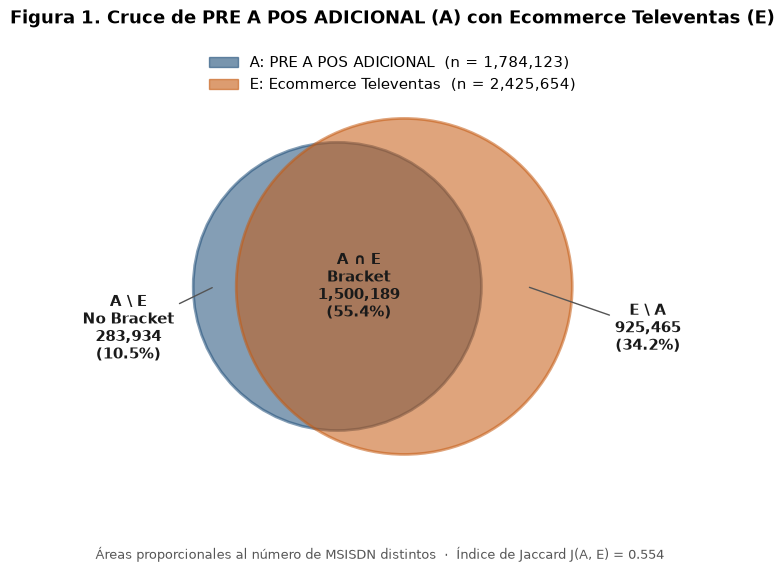

In [7]:
# Figura 1. Diagrama de Venn: PRE A POS ADICIONAL (A) vs Ecommerce Televentas (E)
n_solo_a = len(solo_df3)                       # A \ E  -> No Bracket
n_solo_e = len(solo_df4)                       # E \ A
n_inter  = len(valores_df3) - len(solo_df3)    # A ∩ E  -> Bracket

diagrama_venn(
    n_solo_a, n_inter, n_solo_e,
    "PRE A POS ADICIONAL", "Ecommerce Televentas", "A", "E",
    "Figura 1. Cruce de PRE A POS ADICIONAL (A) con Ecommerce Televentas (E)",
    "A \\ E\nNo Bracket", "A ∩ E\nBracket", "E \\ A",
)

### 4.1 Exportación de la base No Bracket

In [8]:
from pathlib import Path

carpeta_resultados = Path("resultados bases")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

msisdn_limpio = (
    df3["MSISDN"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

base_no_bracket = df3[msisdn_limpio.isin(solo_df3)].copy()
archivo = carpeta_resultados / "base no bracket.csv"

base_no_bracket.to_csv(archivo, index=False, encoding="utf-8-sig")

print(f"Registros exportados: {len(base_no_bracket):,}")
print(f"Archivo guardado en: {archivo.resolve()}")

Registros exportados: 283,934
Archivo guardado en: C:\Users\danie\Downloads\resultados bases\base no bracket.csv


## 5. Cruce II de Pre a Home

**Definición:** $\text{Pre a Home} = H \setminus E$

Se buscan los registros de *PRE A HOME* que **no** están en *Ecommerce Televentas*. A este conjunto se le llama **base Pre a Home**.

In [9]:
msisdn_df1 = (
    df1["MSISDN"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True).dropna()
)

valores_df1 = set(msisdn_df1)
valores_df4 = set(msisdn_df4)

solo_df1_vs_df4 = valores_df1 - valores_df4
solo_df4_vs_df1 = valores_df4 - valores_df1

print(f"MSISDN de df1 que no están en df4: {len(solo_df1_vs_df4):,}")
print(f"MSISDN de df4 que no están en df1: {len(solo_df4_vs_df1):,}")
print(f"Total de MSISDN distintos que no coinciden: {len(solo_df1_vs_df4 | solo_df4_vs_df1):,}")

MSISDN de df1 que no están en df4: 1,162,392
MSISDN de df4 que no están en df1: 2,425,654
Total de MSISDN distintos que no coinciden: 3,588,046


**Resultado.** $|H \setminus E| = 1{,}162{,}392$ registros en la base Pre a Home.

> **Observación metodológica.** Como $|E \setminus H| = |E| = 2{,}425{,}654$, la intersección es vacía ($H \cap E = \varnothing$) y la base Pre a Home coincide con la totalidad de `df1`: el cruce no excluye ningún registro. Una intersección nula entre dos bases de más de un millón de líneas conviene validarla (por ejemplo, confirmando que el formato del MSISDN es comparable entre ambas fuentes).

#### Diagrama de Venn

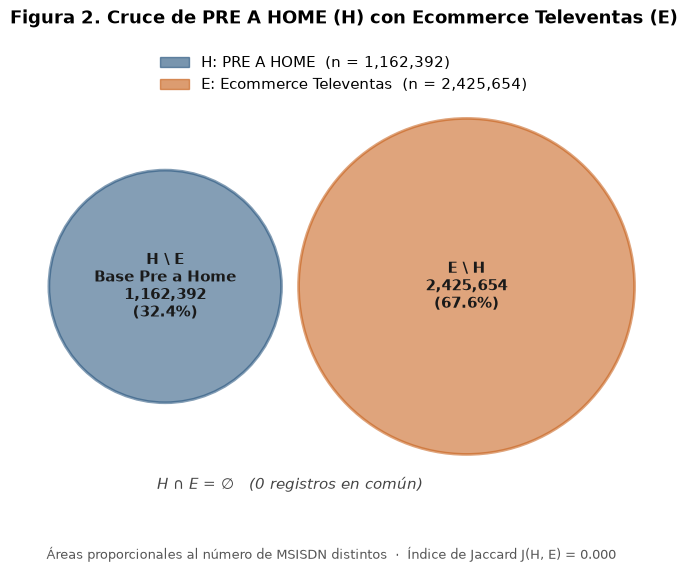

In [10]:
# Figura 2. Diagrama de Venn: PRE A HOME (H) vs Ecommerce Televentas (E)
n_solo_h  = len(solo_df1_vs_df4)                          # H \ E  -> Base Pre a Home
n_solo_e2 = len(solo_df4_vs_df1)                          # E \ H
n_inter_h = len(valores_df1) - len(solo_df1_vs_df4)       # H ∩ E

diagrama_venn(
    n_solo_h, n_inter_h, n_solo_e2,
    "PRE A HOME", "Ecommerce Televentas", "H", "E",
    "Figura 2. Cruce de PRE A HOME (H) con Ecommerce Televentas (E)",
    "H \\ E\nBase Pre a Home", "H ∩ E", "E \\ H",
)

### 5.1 Exportación de la base Pre a Home

In [11]:
msisdn_df1_limpio = (
    df1["MSISDN"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

base_pre_a_home = df1[msisdn_df1_limpio.isin(solo_df1_vs_df4)].copy()
archivo_pre_a_home = carpeta_resultados / "base pre a home.csv"

base_pre_a_home.to_csv(archivo_pre_a_home, index=False, encoding="utf-8-sig")

print(f"Registros exportados: {len(base_pre_a_home):,}")
print(f"Archivo guardado en: {archivo_pre_a_home.resolve()}")

Registros exportados: 1,162,392
Archivo guardado en: C:\Users\danie\Downloads\resultados bases\base pre a home.csv


## 6. Cruce III de Bracket

**Definición:** $\text{Bracket} = A \cap E$

Se buscan los registros que **sí** se cruzan entre *PRE A POS ADICIONAL* y *Ecommerce Televentas*. A este conjunto se le llama **Brackets**.

In [12]:
# Limpia los números para comparar igual
# Limpia los números para comparar igual
msisdn_df3 = (
    df3["MSISDN"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .dropna()
)

msisdn_df4 = (
    df4["msisdn"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .dropna()
)

# Valores que sí coinciden entre df3 y df4
cruzan = set(msisdn_df3) & set(msisdn_df4)

print(f"Cantidad que sí cruzan entre df3 y df4: {len(cruzan):,}")

# Registros completos que cruzan
df3_cruce = df3[
    df3["MSISDN"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .isin(cruzan)
].copy()

df4_cruce = df4[
    df4["msisdn"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .isin(cruzan)
].copy()

# Opcional: guardar los MSISDN cruzados
msisdn_cruzados = list(cruzan)

msisdn_df4 = (
    df4["msisdn"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .dropna()
)


Cantidad que sí cruzan entre df3 y df4: 1,500,189


**Resultado.** $|A \cap E| = 1{,}500{,}189$ registros Bracket, valor que coincide con la región central de la Figura 1.

### 6.1 Unión de las bases cruzadas (*inner join*)

Se unen, por MSISDN, los registros de $A$ y de $E$ que sí cruzan (`df3_cruce` y `df4_cruce`), con los sufijos `_prepos` y `_ecommerce` para las columnas de igual nombre. El resultado (`df_merge`) tiene **1,500,189 filas × 74 columnas**; que el número de filas sea igual a $|A \cap E|$ confirma una relación uno a uno entre las llaves.

In [13]:
df_merge = df3_cruce.merge(
    df4_cruce,
    left_on="MSISDN",
    right_on="msisdn",
    how="inner",
    suffixes=("_prepos", "_ecommerce")
)

print(f"Registros unidos: {len(df_merge):,}")

Registros unidos: 1,500,189


In [14]:
df_merge

,MSISDN,Unnamed: 0,NOMBRE_CLIENTE,msisdn,AUDIENCIA,SUBAUDIENCIA,OFERTA,PERIODO,CEDULA,REGIONAL,...,prom_cons_gbs_tres_meses,min_cons_gbs_tres_meses,max_cons_tot_mns_tres_meses,prom_cons_tot_mns_tres_meses,min_cons_tot_mns_tres_meses,prom_cons_mns_int_tres_meses,prom_cons_mns_off_tres_meses,prom_cons_mns_on_tres_meses,prom_cons_mns_fxn_tres_meses,motivo_retiro_seis_meses
0,3002035477,32574,To Be Determined,3002035477,PREPAGO PRE A POS TOAD,UP TOAD,0. TOAD,202610,To Be Determined,COSTA,...,60.0,57.0,469.0,328.0,233.0,0.0,34.0,294.0,0.0,NaN
1,3001928779,29739,To Be Determined,3001928779,PREPAGO PRE A POS TOAD,UP TOAD,0. TOAD,202610,To Be Determined,COSTA,...,9.0,7.0,210.0,167.0,107.0,0.0,55.0,104.0,7.0,NaN
2,3001310511,10117,To Be Determined,3001310511,PREPAGO PRE A POS TOAD,UP TOAD,0. TOAD,202610,To Be Determined,COSTA,...,9.0,8.0,216.0,109.0,29.0,0.0,2.0,107.0,0.0,NaN
3,3001366048,2181199,To Be Determined,3001366048,PREPAGO PRE A POS SUPER MARIO,UP SUPER MARIO,2. SUPER MARIO,202610,To Be Determined,COSTA,...,7.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
4,3001413446,13262,To Be Determined,3001413446,PREPAGO PRE A POS TOAD,UP TOAD,0. TOAD,202610,To Be Determined,COSTA,...,33.0,13.0,26.0,16.0,11.0,0.0,14.0,2.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1500184,3022285325,447061,To Be Determined,3022285325,PREPAGO PRE A POS SUPER MARIO,UP SUPER MARIO,2. SUPER MARIO,202610,To Be Determined,ANDINA,...,12.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,NaN
1500185,3122430439,721829,To Be Determined,3122430439,PREPAGO PRE A POS TOAD,UP TOAD,0. TOAD,202610,To Be Determined,COSTA,...,2.0,1.0,194.0,138.0,90.0,0.0,45.0,93.0,0.0,NaN
1500186,3000196219,1093964,To Be Determined,3000196219,PREPAGO PRE A POS SUPER MARIO,UP SUPER MARIO,2. SUPER MARIO,202610,To Be Determined,ANDINA,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
1500187,3000280532,1192628,To Be Determined,3000280532,PREPAGO PRE A POS SUPER MARIO,UP SUPER MARIO,2. SUPER MARIO,202610,To Be Determined,ANDINA,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN


## 7. Consolidación de la base final

### 7.1 Unión de PRE A POS limpia y PRE A POS de inicio de mes

Se carga la base $P'$ (`df5`) y se concatena con $P$ (`df2`): $\text{df\_nuevo} = P \parallel P'$, que resulta en **2,208,612 filas × 13 columnas**. `pandas` emite un `DtypeWarning` por tipos mixtos en la columna `SUM_RVNU_TOT`.

In [15]:
df5=pd.read_csv(r"C:\Users\danie\Downloads\Migra Tigo\PRE A POS.csv")

C:\Users\danie\AppData\Local\Temp\ipykernel_7960\4078152688.py:1: DtypeWarning: Columns (4: SUM_RVNU_TOT) have mixed types. Specify dtype option on import or set low_memory=False.
  df5=pd.read_csv(r"C:\Users\danie\Downloads\Migra Tigo\PRE A POS.csv")


In [16]:
df_nuevo = pd.concat([df2, df5], ignore_index=True)

In [17]:
df_nuevo

,MSISDN,Unnamed: 0,PERIODO,ANTIGUEDAD,SUM_RVNU_TOT,REGIONAL,DEPARTAMENTO,MUNICIPIO,QUINCENA,PERFIL,ID_PLAN_RECOMMENDED_1,ID_PLAN_RECOMMENDED_2,ID_PLAN_RECOMMENDED_3
0,3001000485,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3001000849,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3001000853,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3001000901,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3001001267,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2208607,3245074825,1104301.0,202610.0,16.0,NaN,ANDINA,ANTIOQUIA,TURBO,NaN,1. 0-5k,19.9K/7751/25GB,24.9K/7761/30GB,NaN
2208608,3046327056,1104302.0,202610.0,19.0,NaN,ANDINA,ANTIOQUIA,MEDELLÍN,NaN,1. 0-5k,19.9K/7751/25GB,24.9K/7761/30GB,NaN
2208609,3046327344,1104303.0,202610.0,49.0,NaN,ANDINA,CALDAS,VITERBO,NaN,1. 0-5k,19.9K/7751/25GB,24.9K/7761/30GB,NaN
2208610,3046327094,1104304.0,202610.0,16.0,NaN,COSTA,ATLÁNTICO,SOLEDAD,NaN,1. 0-5k,19.9K/7751/25GB,24.9K/7761/30GB,NaN


### 7.2 Unión de `df_nuevo` y `df_merge`

Se concatenan las filas de la base PRE A POS consolidada (`df_nuevo`) con las de los Bracket (`df_merge`), con lo que se obtiene `df_final` (2,208,612 + 1,500,189 = 3,708,801 filas).

In [18]:
df_final = pd.concat([df_nuevo, df_merge], ignore_index=True)

### 7.3 Selección del bracket de menor valor

Para cada fila de `df_final` se extrae el precio inicial de los planes recomendados (`ID_PLAN_RECOMMENDED_1` e `ID_PLAN_RECOMMENDED_2`) y se conserva el **menor**. El resultado es `df_msisdn_bracket`, con el MSISDN, el bracket asignado y el total de registros de su categoría, junto con `df_conteo_brackets`, que resume una fila por bracket.

In [19]:
columnas_plan = [
    "ID_PLAN_RECOMMENDED_1",
    "ID_PLAN_RECOMMENDED_2",
]

# Extraer el precio inicial de cada plan y convertirlo a número
precios = df_final[columnas_plan].apply(
    lambda columna: pd.to_numeric(
        columna.astype("string").str.extract(r"(\d+(?:\.\d+)?)", expand=False),
        errors="coerce",
    )
)

# min(axis=1) ignora los valores faltantes; si ambos faltan, el resultado queda vacío
df_msisdn_bracket = pd.DataFrame({
    "MSISDN": df_final["MSISDN"].to_numpy(),
    "bracket": precios.min(axis=1).to_numpy(),
})

# Añadir a cada fila el total de registros de su bracket
conteos = df_msisdn_bracket["bracket"].value_counts()
df_msisdn_bracket["cantidad_registros_bracket"] = (
    df_msisdn_bracket["bracket"].map(conteos)
)

# Resumen: una fila por bracket
df_conteo_brackets = (
    df_msisdn_bracket.dropna(subset=["bracket"])
    .groupby("bracket")
    .size()
    .rename("cantidad_registros")
    .reset_index()
    .sort_values("bracket")
)

display(df_msisdn_bracket)
display(df_conteo_brackets)

,MSISDN,bracket,cantidad_registros_bracket
0,3001000485,NaN,NaN
1,3001000849,NaN,NaN
2,3001000853,NaN,NaN
3,3001000901,NaN,NaN
4,3001001267,NaN,NaN
...,...,...,...
3708796,3022285325,29.9,106111.0
3708797,3122430439,34.9,205911.0
3708798,3000196219,19.9,1539689.0
3708799,3000280532,19.9,1539689.0


,bracket,cantidad_registros
0,19.9,1539689
1,24.9,205058
2,29.9,106111
3,34.9,205911
4,39.9,66843
5,43.9,107129
6,47.9,136882
7,53.9,124798
8,69.9,112074


### 7.4 Exportación de los brackets

Se genera un archivo CSV por cada categoría de bracket en la carpeta `resultados bases`, con las columnas `MSISDN`, `bracket` y `cantidad_registros_bracket`. Las filas sin bracket asignado no se exportan.

In [20]:
for bracket, grupo in df_msisdn_bracket.dropna(subset=["bracket"]).groupby("bracket", sort=True):
    archivo = carpeta_resultados / f"bracket_{bracket:g}.csv"
    grupo.to_csv(archivo, index=False, encoding="utf-8-sig")
    print(f"Guardado: {archivo}")

Guardado: resultados bases\bracket_19.9.csv
Guardado: resultados bases\bracket_24.9.csv
Guardado: resultados bases\bracket_29.9.csv
Guardado: resultados bases\bracket_34.9.csv
Guardado: resultados bases\bracket_39.9.csv
Guardado: resultados bases\bracket_43.9.csv
Guardado: resultados bases\bracket_47.9.csv
Guardado: resultados bases\bracket_53.9.csv
Guardado: resultados bases\bracket_69.9.csv


### 7.5 Verificación de las cantidades exportadas

Se vuelven a leer los archivos exportados y se compara su número de filas con el esperado según `df_msisdn_bracket`. La verificación resulta **exitosa en las nueve categorías**.

In [21]:
conteos_esperados = (
    df_msisdn_bracket
    .dropna(subset=["bracket"])
    .groupby("bracket", sort=True)
    .size()
    .rename("esperado")
)

conteos_guardados = {}
for archivo in carpeta_resultados.glob("bracket_*.csv"):
    bracket = float(archivo.stem[len("bracket_"):])
    conteos_guardados[bracket] = len(pd.read_csv(archivo))

resumen = pd.DataFrame({"esperado": conteos_esperados}).join(
    pd.Series(conteos_guardados, name="en_archivo"),
    how="outer",
).fillna(0).astype(int)

resumen["correcto"] = resumen["esperado"] == resumen["en_archivo"]

print(resumen.sort_index().to_string())
print(f"\n¿Todas las cantidades coinciden? {resumen['correcto'].all()}")

         esperado  en_archivo  correcto
bracket                                
19.9      1539689     1539689      True
24.9       205058      205058      True
29.9       106111      106111      True
34.9       205911      205911      True
39.9        66843       66843      True
43.9       107129      107129      True
47.9       136882      136882      True
53.9       124798      124798      True
69.9       112074      112074      True

¿Todas las cantidades coinciden? True


### 7.6 Resultados: distribución de los brackets

Las bases `df_final` y `df_msisdn_bracket` ya no residen en memoria. Para que el notebook conserve el resultado sin necesidad de recalcularlas, las cifras de las secciones 7.3 a 7.5 se registran a continuación tal como fueron obtenidas en la ejecución, junto con una validación interna de consistencia.

| Indicador | Valor |
|:--|--:|
| Filas de `df_final` | 3,708,801 |
| Filas con bracket asignado | 2,604,495 (70.2 %) |
| Filas sin bracket (ambos planes vacíos) | 1,104,306 (29.8 %) |
| Categorías de bracket | 9 |
| Rango de brackets | 19.9 a 69.9 |

#### Tabla 1. Registros por bracket y archivo exportado

In [22]:
import pandas as pd

# Resultados registrados de las secciones 7.3 a 7.5 (df_final ya no está en memoria).
TOTAL_FILAS_DF_FINAL = 3_708_801

df_conteo_brackets = pd.DataFrame({
    "bracket": [19.9, 24.9, 29.9, 34.9, 39.9, 43.9, 47.9, 53.9, 69.9],
    "cantidad_registros": [1_539_689, 205_058, 106_111, 205_911, 66_843,
                           107_129, 136_882, 124_798, 112_074],
})

total_con_bracket = int(df_conteo_brackets["cantidad_registros"].sum())
total_sin_bracket = TOTAL_FILAS_DF_FINAL - total_con_bracket

# Control de consistencia frente a lo observado en las secciones 7.3 y 7.5
assert total_con_bracket == 2_604_495
assert total_sin_bracket == 1_104_306

df_conteo_brackets["pct_con_bracket"] = df_conteo_brackets["cantidad_registros"] / total_con_bracket * 100
df_conteo_brackets["pct_acumulado"] = df_conteo_brackets["pct_con_bracket"].cumsum()
df_conteo_brackets["pct_df_final"] = df_conteo_brackets["cantidad_registros"] / TOTAL_FILAS_DF_FINAL * 100

tabla_brackets = pd.DataFrame({
    "Bracket": df_conteo_brackets["bracket"].map(lambda b: f"{b:g}"),
    "Registros": df_conteo_brackets["cantidad_registros"].map("{:,}".format),
    "% de filas con bracket": df_conteo_brackets["pct_con_bracket"].map("{:.1f} %".format),
    "% acumulado": df_conteo_brackets["pct_acumulado"].map("{:.1f} %".format),
    "% de df_final": df_conteo_brackets["pct_df_final"].map("{:.1f} %".format),
    "Archivo exportado": df_conteo_brackets["bracket"].map(lambda b: f"bracket_{b:g}.csv"),
    "Verificación": "Correcta",
})

display(tabla_brackets)

print(f"Total con bracket asignado : {total_con_bracket:>10,}  ({total_con_bracket / TOTAL_FILAS_DF_FINAL:.1%} de df_final)")
print(f"Total sin bracket          : {total_sin_bracket:>10,}  ({total_sin_bracket / TOTAL_FILAS_DF_FINAL:.1%} de df_final)")
print(f"Total de filas df_final    : {TOTAL_FILAS_DF_FINAL:>10,}")

,Bracket,Registros,% de filas con bracket,% acumulado,% de df_final,Archivo exportado,Verificación
0,19.9,"1,539,689",59.1 %,59.1 %,41.5 %,bracket_19.9.csv,Correcta
1,24.9,"205,058",7.9 %,67.0 %,5.5 %,bracket_24.9.csv,Correcta
2,29.9,"106,111",4.1 %,71.1 %,2.9 %,bracket_29.9.csv,Correcta
3,34.9,"205,911",7.9 %,79.0 %,5.6 %,bracket_34.9.csv,Correcta
4,39.9,"66,843",2.6 %,81.5 %,1.8 %,bracket_39.9.csv,Correcta
5,43.9,"107,129",4.1 %,85.6 %,2.9 %,bracket_43.9.csv,Correcta
6,47.9,"136,882",5.3 %,90.9 %,3.7 %,bracket_47.9.csv,Correcta
7,53.9,"124,798",4.8 %,95.7 %,3.4 %,bracket_53.9.csv,Correcta
8,69.9,"112,074",4.3 %,100.0 %,3.0 %,bracket_69.9.csv,Correcta


Total con bracket asignado :  2,604,495  (70.2% de df_final)
Total sin bracket          :  1,104,306  (29.8% de df_final)
Total de filas df_final    :  3,708,801


#### Figura 3. Distribución de los registros por bracket

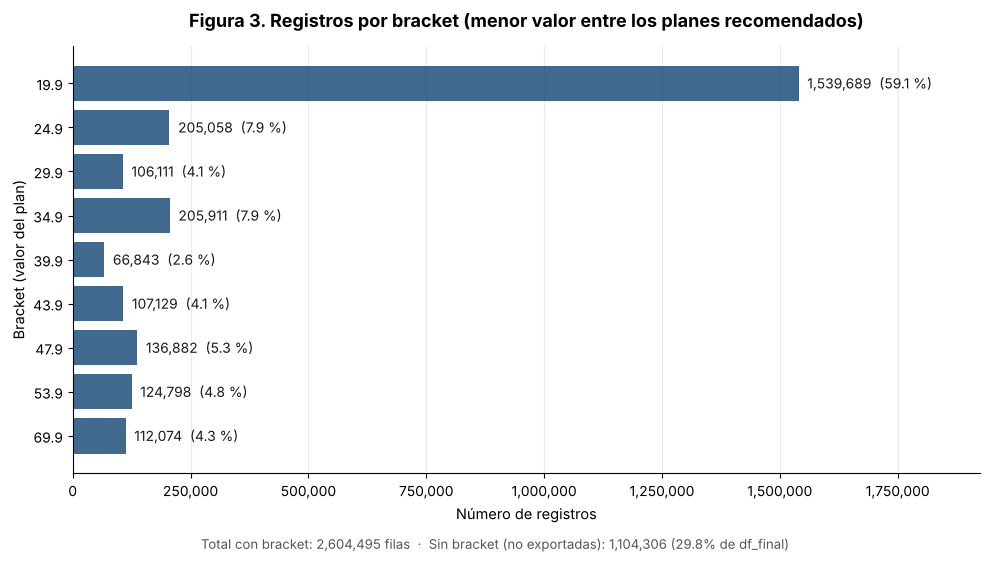

In [23]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 5.6))

etiquetas = [f"{b:g}" for b in df_conteo_brackets["bracket"]]
valores = df_conteo_brackets["cantidad_registros"]
barras = ax.barh(etiquetas, valores, color="#1F4E79", alpha=0.85)
ax.invert_yaxis()

margen = valores.max() * 0.012
for barra, n, p in zip(barras, valores, df_conteo_brackets["pct_con_bracket"]):
    ax.text(barra.get_width() + margen, barra.get_y() + barra.get_height() / 2,
            f"{n:,}  ({p:.1f} %)", va="center", fontsize=10, color="#1a1a1a")

ax.set_xlim(0, valores.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("Número de registros", fontsize=10.5)
ax.set_ylabel("Bracket (valor del plan)", fontsize=10.5)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)

ax.set_title("Figura 3. Registros por bracket (menor valor entre los planes recomendados)",
             fontsize=13, weight="bold", pad=14)
fig.text(0.5, 0.01,
         f"Total con bracket: {total_con_bracket:,} filas  ·  Sin bracket (no exportadas): "
         f"{total_sin_bracket:,} ({total_sin_bracket / TOTAL_FILAS_DF_FINAL:.1%} de df_final)",
         ha="center", fontsize=9.5, color="#555555")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

**Lectura de resultados**

- El bracket **19.9** concentra 1,539,689 registros, es decir, el **59.1 %** de las filas con bracket asignado y más de siete veces el volumen del siguiente bracket (34.9, con 205,911).
- Los ocho brackets restantes suman 1,064,806 registros (**40.9 %**), distribuidos entre 66,843 (bracket 39.9) y 205,911 (bracket 34.9).
- Las nueve cantidades exportadas coinciden con las esperadas (sección 7.5), por lo que no hay pérdida ni duplicación de filas entre la base en memoria y los archivos.
- Las **1,104,306 filas sin bracket** (29.8 % de `df_final`) no tienen ningún plan recomendado y no forman parte de los archivos de salida (véase la sección 10).

## 8. Criterio de selección del bracket

Sobre `df_final`, para cada MSISDN se comparan las dos columnas con los brackets recomendados (`ID_PLAN_RECOMMENDED_1` e `ID_PLAN_RECOMMENDED_2`) y se conserva el de **menor valor**. La implementación está en la sección 7.3 y opera de la siguiente forma:

1. Se extrae de cada identificador de plan su precio inicial (primer valor numérico, con o sin decimales) y se convierte a número.
2. Se toma el mínimo por fila (`min(axis=1)`), que ignora los valores faltantes; si ambas columnas están vacías, el bracket queda sin asignar (`NaN`).
3. Se agrega a cada fila el total de registros de su bracket y se exporta un archivo por categoría (sección 7.4), cuyas cantidades se validan contra la base en memoria (sección 7.5).

**Resultado.** Se obtienen **9 categorías de bracket** (19.9, 24.9, 29.9, 34.9, 39.9, 43.9, 47.9, 53.9 y 69.9) con 2,604,495 filas asignadas; el detalle se presenta en la sección 7.6.

> **Nota metodológica.** Actualmente no existen métodos de imputación de datos faltantes, aspecto importante de revisar. Como consecuencia, las 1,104,306 filas de `df_final` que no tienen ninguno de los dos planes recomendados quedan sin bracket y no se exportan.

## 9. Verificación de consistencia y resumen

### 9.1 Identidades de partición

| Identidad | Cálculo | Resultado |
|:--|:--|:--|
| $\lvert A \rvert = \lvert A \setminus E \rvert + \lvert A \cap E \rvert$ | 283,934 + 1,500,189 | 1,784,123 ✔ (= registros de `df3`) |
| $\lvert E \rvert = \lvert E \setminus A \rvert + \lvert A \cap E \rvert$ | 925,465 + 1,500,189 | 2,425,654 ✔ (= registros de `df4`) |
| $\lvert H \rvert = \lvert H \setminus E \rvert + \lvert H \cap E \rvert$ | 1,162,392 + 0 | 1,162,392 ✔ (= registros de `df1`) |
| $\lvert A \bowtie E \rvert = \lvert A \cap E \rvert$ | 1,500,189 = 1,500,189 | ✔ |
| Filas con bracket + filas sin bracket = filas de `df_final` | 2,604,495 + 1,104,306 | 3,708,801 ✔ |
| Suma de los 9 brackets = filas con bracket | 1,539,689 + 205,058 + 106,111 + 205,911 + 66,843 + 107,129 + 136,882 + 124,798 + 112,074 | 2,604,495 ✔ |
| Filas esperadas = filas en archivo (por bracket) | 9 de 9 categorías | ✔ |

Como los conteos de MSISDN distintos coinciden con el número de registros de cada fuente, **MSISDN funciona como llave sin duplicados** en $H$, $A$ y $E$.

### 9.2 Medidas de asociación entre $A$ y $E$

- Proporción de $A$ contenida en $E$: **84.1 %**
- Proporción de $E$ contenida en $A$: **61.8 %**
- Índice de Jaccard: $J(A,E) = \dfrac{|A \cap E|}{|A \cup E|} = \dfrac{1{,}500{,}189}{2{,}709{,}588} \approx 0.554$

### 9.3 Resumen de resultados

| Base | Definición | Registros | Salida |
|:--|:--:|--:|:--|
| No Bracket | $A \setminus E$ | 283,934 | `base no bracket.csv` |
| Pre a Home | $H \setminus E$ | 1,162,392 | `base pre a home.csv` |
| Bracket | $A \cap E$ | 1,500,189 | `df_merge` (insumo de `df_final`) |
| PRE A POS consolidada | $P \parallel P'$ | 2,208,612 | `df_nuevo` (insumo de `df_final`) |
| Base final | `df_nuevo` $\parallel$ `df_merge` | 3,708,801 | `df_final` (insumo de la selección de bracket) |
| Filas con bracket asignado | mín. de los planes recomendados | 2,604,495 | 9 archivos `bracket_<valor>.csv` |
| Filas sin bracket | ambos planes vacíos | 1,104,306 | No se exportan |

## 10. Limitaciones y recomendaciones

- **Datos faltantes sin imputar.** Al concatenar, las filas provenientes de PRE A POS (`df2`) quedan con valores faltantes en columnas como `PERIODO`, `ANTIGUEDAD` y `REGIONAL`. Se recomienda definir un criterio de imputación o de exclusión.
- **Tipos mixtos.** `pandas` advirtió tipos mixtos en `PERFIL` (`df4`) y `SUM_RVNU_TOT` (`df5`); se sugiere fijar `dtype` explícitos o usar `low_memory=False` al leer.
- **Validación de $H \cap E = \varnothing$.** Confirmar que el formato del MSISDN es equivalente en ambas bases antes de dar por válido el resultado.
- **Normalización repetida.** La limpieza del MSISDN se reescribe en varias celdas; centralizarla en una función reduciría el riesgo de inconsistencias.
- **Rutas locales.** Las rutas de lectura son absolutas (Windows) y la carpeta `resultados bases` es relativa al directorio de trabajo; conviene parametrizarlas para reproducir el proceso en otro equipo.
- **Filas sin bracket.** 1,104,306 filas de `df_final` (29.8 %) no tienen ninguno de los dos planes recomendados y quedan fuera de la exportación. Esta cifra coincide exactamente con el número de registros de una de las dos fuentes PRE A POS (1,104,306), por lo que conviene revisar qué porción de `df_nuevo` incorpora los planes recomendados.
- **Unicidad del MSISDN en `df_final`.** La concatenación de $P$, $P'$ y el *inner join* no garantiza un MSISDN por fila (por ejemplo, una misma línea presente en ambas versiones de PRE A POS). Los 2,604,495 registros con bracket son filas y no necesariamente líneas distintas; se recomienda validar `df_msisdn_bracket["MSISDN"].is_unique` antes de entregar los archivos.
- **Extracción del precio del plan.** El bracket se obtiene tomando el primer valor numérico del identificador del plan; se recomienda contrastarlo contra el catálogo oficial de planes para descartar identificadores con numeración distinta al precio.
- **Persistencia de la base consolidada.** `df_final` y `df_msisdn_bracket` no se guardan en disco, por lo que cualquier ajuste exige recalcular todo el proceso. Se sugiere persistir `df_msisdn_bracket` (por ejemplo, en formato Parquet) como insumo intermedio.
